# QM640 Capstone Interim Report — RQ1 and RQ2
**Transformer DGA fault classification and explainability | Preliminary, reproducible analysis**

**Research questions.** RQ1 compares four baseline machine-learning classifiers for six-category transformer DGA fault classification. RQ2 evaluates global feature importance using permutation importance and SHAP, including internal ranking stability.

**Data:** `QM640_Public_DGA_Fault_Dataset.xlsx` (589 rows), retrieved from the [project GitHub repository](https://github.com/irurama2018-coder/M640-Transformer-AI-Capstone/blob/main/QM640_Public_DGA_Fault_Dataset.xlsx).

**Crucial Methodological Limitations:**
* **Unverified Provenance:** The project repository is **not verified as the original dataset publisher**. Original source, licensing, DGA concentration units, and fault-label derivation are unverified and require confirmation before final academic citation.
* **Unverified Transformer-Level Independence:** The dataset lacks verified transformer IDs and sampling dates. Because transformer-level and transformer-independent partitions cannot be established, a random stratified split may suffer from leakage and cannot demonstrate true generalization on unseen transformers.

**Important scope:** All results below are exploratory. No utility maintenance, energy-loss, or CAPEX outcomes are established here.

## 1. Data loading and quality assessment
Run the notebook top-to-bottom in Google Colab. The public dataset must remain accessible at the URL below.

### Dataset context — source verification pending
The 589-row workbook was obtained via the project repository; the upstream secondary source is [alan-456/transformer-fault-dataset](https://github.com/alan-456/transformer-fault-dataset). Original record-level provenance, measurement units (often ppm in DGA practice), label-generation methodology, redistribution permissions, and asset independence have **not** been independently confirmed. IEC 60599 and IEEE C57.104 are background interpretation standards, **not proof** that these labels were assigned using either standard. Treat results as exploratory, not field-validated.

In [ ]:
import os
import pandas as pd
import urllib.request

local_filename = "QM640_Public_DGA_Fault_Dataset.xlsx"
dataset_url = (
    "https://raw.githubusercontent.com/"
    "irurama2018-coder/M640-Transformer-AI-Capstone/"
    "main/QM640_Public_DGA_Fault_Dataset.xlsx"
)

# Local-first loading implementation
if not os.path.exists(local_filename):
    print(f"Local file not found. Downloading dataset from {dataset_url}...")
    urllib.request.urlretrieve(dataset_url, local_filename)
    print("Download completed and saved locally.")
else:
    print(f"Loading dataset from local copy: {local_filename}")

df = pd.read_excel(local_filename)

print("Dataset shape:", df.shape)
print(df.columns.tolist())
print("\nFirst five records:")
display(df.head())
print("\nMissing values by column:")
print(df.isnull().sum())
print("\nExact duplicate rows:", df.duplicated().sum())

# Retain duplicate inspection from the removed redundant cells
duplicate_mask = df.duplicated(keep=False)
print("\nAll rows belonging to duplicate groups:", duplicate_mask.sum())
display(df.loc[duplicate_mask].sort_values(by=df.columns.tolist()))

Loading dataset from local copy: QM640_Public_DGA_Fault_Dataset.xlsx
Dataset shape: (589, 6)
['H2', 'CH4', 'C2H6', 'C2H4', 'C2H2', '故障类型']

First five records:


,H2,CH4,C2H6,C2H4,C2H2,故障类型
0,1458.0,9.0,1812.0000,0.0001,0.0001,PD
1,2240.0,157.0,90.0000,157.0000,45.0000,PD
2,73.0,8.0,4.0000,2.0000,12.0000,PD
3,235.0,16.0,0.0001,35.0000,0.0001,PD
4,9340.0,995.0,60.0000,6.0000,7.0000,PD



Missing values by column:
H2      0
CH4     0
C2H6    0
C2H4    0
C2H2    0
故障类型    0
dtype: int64

Exact duplicate rows: 2

All rows belonging to duplicate groups: 4


,H2,CH4,C2H6,C2H4,C2H2,故障类型
456,120.0,31.0,0.0001,66.0,94.0,D2
481,120.0,31.0,0.0001,66.0,94.0,D2
154,7020.0,1850.0,0.0001,2960.0,4410.0,D2
180,7020.0,1850.0,0.0001,2960.0,4410.0,D2


In [ ]:
import os
import pandas as pd

# Ensure df is loaded safely
local_filename = "QM640_Public_DGA_Fault_Dataset.xlsx"
if 'df' not in globals():
    if os.path.exists(local_filename):
        df = pd.read_excel(local_filename)
    else:
        raise FileNotFoundError(f"{local_filename} not found. Please run cell ceed623f first to download it.")

print("=== DATA QUALITY CHECK ===")
print(f"Total rows in dataset: {len(df)}")
print(f"Total columns: {len(df.columns)}")

print("\nMissing values per column:")
display(df.isnull().sum().to_frame(name='Missing Count'))

print(f"\nNumber of exact duplicate rows: {df.duplicated().sum()}")
if df.duplicated().sum() > 0:
    print("Sample of duplicated rows:")
    display(df[df.duplicated(keep=False)].sort_values(by=df.columns.tolist()).head(4))

=== DATA QUALITY CHECK ===
Total rows in dataset: 589
Total columns: 6

Missing values per column:


,Missing Count
H2,0
CH4,0
C2H6,0
C2H4,0
C2H2,0
故障类型,0



Number of exact duplicate rows: 2
Sample of duplicated rows:


,H2,CH4,C2H6,C2H4,C2H2,故障类型
456,120.0,31.0,0.0001,66.0,94.0,D2
481,120.0,31.0,0.0001,66.0,94.0,D2
154,7020.0,1850.0,0.0001,2960.0,4410.0,D2
180,7020.0,1850.0,0.0001,2960.0,4410.0,D2


### Dataset integrity and duplicate review
Exact duplicate rows are excluded from the primary exploratory analysis to reduce duplicate leakage risk. Without transformer IDs, repeated legitimate measurements cannot be distinguished; therefore, retain the original-data comparison as a sensitivity analysis.

### Deduplication and data quality validation

In [ ]:
# Exact duplicates are excluded for the primary exploratory baseline;
# this is a modeling choice, not proof they are erroneous measurements.

df_deduplicated = df.drop_duplicates().copy()

print("Original observations:", len(df))
print("Deduplicated observations:",
      len(df_deduplicated))

print("Records removed:",
      len(df) - len(df_deduplicated))

Original observations: 589
Deduplicated observations: 587
Records removed: 2


In [ ]:
# RQ1 — compare raw and deduplicated datasets using dynamically fitted models
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, balanced_accuracy_score, f1_score
import pandas as pd

features = ["H2", "CH4", "C2H6", "C2H4", "C2H2"]
target = "故障类型"

def evaluate_rf(data):
    X0, y0 = data[features], data[target]
    Xt, Xv, yt, yv = train_test_split(X0, y0, test_size=0.20, random_state=42, stratify=y0)
    rf = RandomForestClassifier(n_estimators=200, random_state=42, class_weight="balanced")
    rf.fit(Xt, yt)
    pred = rf.predict(Xv)
    return {"Rows": len(data), "Training": len(Xt), "Holdout": len(Xv),
            "Accuracy": accuracy_score(yv, pred),
            "Balanced Accuracy": balanced_accuracy_score(yv, pred),
            "Macro F1": f1_score(yv, pred, average="macro")}

raw_metrics = evaluate_rf(df)
dedup_metrics = evaluate_rf(df_deduplicated)
comparison_sensitivity = pd.DataFrame([{"Dataset": "Original (sensitivity)", **raw_metrics},
                                       {"Dataset": "Deduplicated (primary)", **dedup_metrics}])
display(comparison_sensitivity.round(4))


,Dataset,Rows,Training,Holdout,Accuracy,Balanced Accuracy,Macro F1
0,Original (sensitivity),589,471,118,0.7712,0.7342,0.7405
1,Deduplicated (primary),587,469,118,0.7627,0.7212,0.7262


In [ ]:
# All values above are calculated from fitted models; no saved/hardcoded scores.
print("Primary baseline: deduplicated data (", len(df_deduplicated), "rows)")
print("Sensitivity comparison is descriptive: train/test partitions differ across datasets.")

Primary baseline: deduplicated data ( 587 rows)
Sensitivity comparison is descriptive: train/test partitions differ across datasets.


<Figure size 800x600 with 0 Axes>

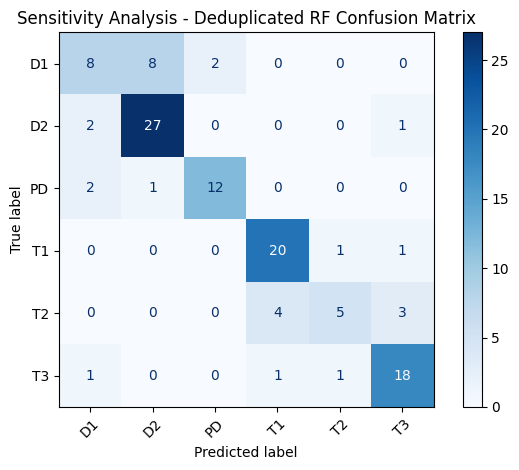

In [ ]:
# Plot confusion matrix for the deduplicated sensitivity analysis model
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import ConfusionMatrixDisplay
import matplotlib.pyplot as plt

# Re-split and fit a model specifically to obtain predictions for the deduplicated dataset
features = ["H2", "CH4", "C2H6", "C2H4", "C2H2"]
target = "故障类型"

Xt, Xv, yt, yv = train_test_split(
    df_deduplicated[features],
    df_deduplicated[target],
    test_size=0.20,
    random_state=42,
    stratify=df_deduplicated[target]
)

rf_d = RandomForestClassifier(n_estimators=200, random_state=42, class_weight="balanced")
rf_d.fit(Xt, yt)
y_pred_d = rf_d.predict(Xv)
y_test_d = yv

plt.figure(figsize=(8, 6))
ConfusionMatrixDisplay.from_predictions(
    y_test_d,
    y_pred_d,
    cmap="Blues",
    xticks_rotation=45
)

plt.title("Sensitivity Analysis - Deduplicated RF Confusion Matrix")
plt.tight_layout()
plt.show()

In [ ]:
# RQ1 - Step 2: Dataset quality verification

# Verify and print the total number of records
print("Total records:", len(df))

# Display the count and distribution of different transformer fault categories
print("\nFault class distribution:")
print(df["故障类型"].value_counts())

# Re-verify and print the count of missing values per feature column
print("\nMissing values:")
print(df.isnull().sum())

# Count and display duplicate observations in the data
print("\nDuplicate records:")
print(df.duplicated().sum())

# Check the schema data types of all feature and target columns
print("\nData types:")
print(df.dtypes)

Total records: 589

Fault class distribution:
故障类型
D2    149
T1    111
T3    104
D1     91
PD     74
T2     60
Name: count, dtype: int64

Missing values:
H2      0
CH4     0
C2H6    0
C2H4    0
C2H2    0
故障类型    0
dtype: int64

Duplicate records:
2

Data types:
H2      float64
CH4     float64
C2H6    float64
C2H4    float64
C2H2    float64
故障类型     object
dtype: object


**Quality observations.** Two exact duplicate rows were identified in the original 589 observations and excluded from the primary exploratory baseline (587 rows). Asset identifiers are unavailable, so true equipment-level independence cannot be established. Check missing-value and class counts in the live outputs above.

## 2. RQ1 — Baseline Random Forest classification
The primary model uses a stratified 80:20 split of the **587-row deduplicated dataset**. Training and holdout sizes, metrics and the confusion matrix are calculated live below. This is an exploratory internal holdout, not independent transformer-level validation.

Training records: 469
Testing records: 118

Accuracy: 0.7627
Balanced accuracy: 0.7212

Classification report:
              precision    recall  f1-score   support

          D1       0.62      0.44      0.52        18
          D2       0.75      0.90      0.82        30
          PD       0.86      0.80      0.83        15
          T1       0.80      0.91      0.85        22
          T2       0.71      0.42      0.53        12
          T3       0.78      0.86      0.82        21

    accuracy                           0.76       118
   macro avg       0.75      0.72      0.73       118
weighted avg       0.75      0.76      0.75       118



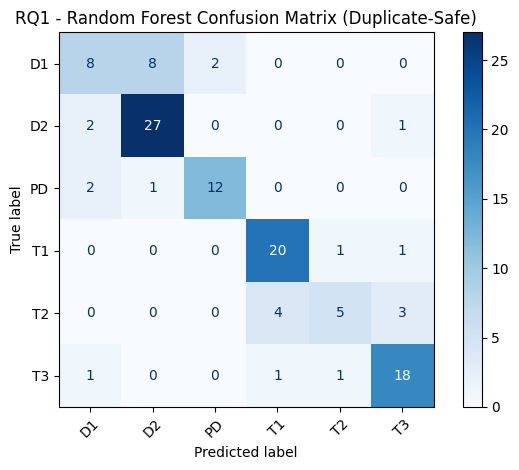

In [ ]:
# RQ1 - Step 3: Random Forest Classification on the consistent Deduplicated Dataset

from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    classification_report,
    ConfusionMatrixDisplay
)
import matplotlib.pyplot as plt

features = ["H2", "CH4", "C2H6", "C2H4", "C2H2"]

# Consistently use df_deduplicated to eliminate data leakage
X = df_deduplicated[features]
y = df_deduplicated["故障类型"]

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

model = RandomForestClassifier(
    n_estimators=200,
    random_state=42,
    class_weight="balanced"
)

model.fit(X_train, y_train)
y_pred = model.predict(X_test)

# Dynamically calculated variables to prevent hardcoded issues
acc_val = accuracy_score(y_test, y_pred)
bal_acc_val = balanced_accuracy_score(y_test, y_pred)

print("Training records:", len(X_train))
print("Testing records:", len(X_test))
print("\nAccuracy:", round(acc_val, 4))
print("Balanced accuracy:", round(bal_acc_val, 4))

print("\nClassification report:")
print(classification_report(y_test, y_pred, zero_division=0))

ConfusionMatrixDisplay.from_predictions(
    y_test,
    y_pred,
    cmap="Blues",
    xticks_rotation=45
)
plt.title("RQ1 - Random Forest Confusion Matrix (Duplicate-Safe)")
plt.tight_layout()
plt.show()

### Class-level performance and operational implications
Use the live `classification_report` and confusion matrix above to identify weak-recall classes, particularly T2 if it remains low. Report exact class-specific recall from the current run rather than copying historical values. False negatives may be consequential in safety-critical transformer diagnostics; deployment would require independent asset-level validation and appropriate engineering oversight.

### RQ1 model comparison
The four models below are baseline configurations, **not exhaustively tuned**. Comparison on the holdout is exploratory and should not be used as a final unbiased model-selection procedure. For a final analysis, tune/select within training-only cross-validation and assess once on an untouched independent test set.

In [ ]:
# RQ1 - Step 4: Compare Four ML Algorithms

import pandas as pd

from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC
from sklearn.ensemble import (
    RandomForestClassifier,
    GradientBoostingClassifier
)
from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    f1_score
)

# Initialize four baseline classifiers for comparison using pipelines where scaling is required
models = {
    "Logistic Regression": make_pipeline(
        StandardScaler(),
        LogisticRegression(max_iter=3000)
    ),
    "Random Forest": RandomForestClassifier(
        n_estimators=200,
        random_state=42,
        class_weight="balanced"
    ),
    "SVM": make_pipeline(
        StandardScaler(),
        SVC(kernel="rbf", class_weight="balanced")
    ),
    "Gradient Boosting": GradientBoostingClassifier(
        random_state=42
    )
}

results = []

# Iterate, train, and capture testing metrics for each classifier
for name, clf in models.items():
    clf.fit(X_train, y_train)
    predictions = clf.predict(X_test)

    results.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test, predictions),
        "Balanced Accuracy": balanced_accuracy_score(
            y_test, predictions
        ),
        "Macro F1": f1_score(
            y_test, predictions, average="macro"
        )
    })

# Consolidate results into a DataFrame and sort by the primary evaluation metric (Macro F1)
comparison = pd.DataFrame(results)
comparison = comparison.sort_values(
    "Macro F1", ascending=False
)

# Display comparison metrics rounded to 4 decimal places
display(comparison.round(4))

,Model,Accuracy,Balanced Accuracy,Macro F1
1,Random Forest,0.7627,0.7212,0.7262
3,Gradient Boosting,0.7288,0.7090,0.7116
0,Logistic Regression,0.4831,0.3937,0.3284
2,SVM,0.2712,0.2512,0.2014


### Training-only five-fold cross-validation
These folds overlap in training observations; the standard deviation describes variation between folds and is not a confidence interval for new transformers.

In [ ]:
# RQ1 - Step 5: Random Forest Cross-Validation
# Use only the training data, preserving the test set for internal validation; this does not establish independent equipment-level generalization.

import numpy as np
import pandas as pd

from sklearn.model_selection import (
    StratifiedKFold,
    cross_validate
)
from sklearn.ensemble import RandomForestClassifier

# Define the stratified 5-fold cross-validation split strategy
cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

# Instantiate the Random Forest model for validation
rf_cv = RandomForestClassifier(
    n_estimators=200,
    random_state=42,
    class_weight="balanced"
)

# Evaluate the model across multiple key metrics on the cross-validation folds
scores = cross_validate(
    rf_cv,
    X_train,
    y_train,
    cv=cv,
    scoring={
        "accuracy": "accuracy",
        "balanced_accuracy": "balanced_accuracy",
        "macro_f1": "f1_macro"
    },
    n_jobs=-1
)

# Organise the fold scores into a display DataFrame
results_cv = pd.DataFrame({
    "Fold": range(1, 6),
    "Accuracy": scores["test_accuracy"],
    "Balanced Accuracy": scores["test_balanced_accuracy"],
    "Macro F1": scores["test_macro_f1"]
})

# Output fold results
display(results_cv.round(4))

# Calculate and print the mean and standard deviation for each metric
print("\nCross-validation summary:")
for metric in ["Accuracy", "Balanced Accuracy", "Macro F1"]:
    print(
        f"{metric}: "
        f"{results_cv[metric].mean():.4f} "
        f"+/- {results_cv[metric].std():.4f}"
    )

,Fold,Accuracy,Balanced Accuracy,Macro F1
0,1,0.7553,0.7350,0.7418
1,2,0.7553,0.7321,0.7453
2,3,0.7872,0.7597,0.7682
3,4,0.7447,0.7170,0.7224
4,5,0.7634,0.7375,0.7420



Cross-validation summary:
Accuracy: 0.7612 +/- 0.0160
Balanced Accuracy: 0.7363 +/- 0.0153
Macro F1: 0.7439 +/- 0.0163


### RQ1 interpretation
The deduplicated primary model's accuracy, balanced accuracy, macro-F1, and training-only five-fold cross-validation scores are calculated in the code cells above. **Do not reuse older 589-record metrics** after changing the data split. The holdout was also used for exploratory model comparison and feature explanation; it is not an untouched final model-selection test. No transformer IDs are available for group-wise validation.

## 3. RQ2 — Permutation importance and SHAP
Permutation importance measures the reduction in macro-F1 after a feature is shuffled; SHAP measures model attribution. The two scores have different scales and should **not** be plotted on a single common quantitative axis.

,DGA Gas,Mean Importance,Standard Deviation
4,C2H2,0.3237,0.0434
3,C2H4,0.3037,0.0372
0,H2,0.1743,0.0398
2,C2H6,0.0738,0.0336
1,CH4,0.0626,0.0203


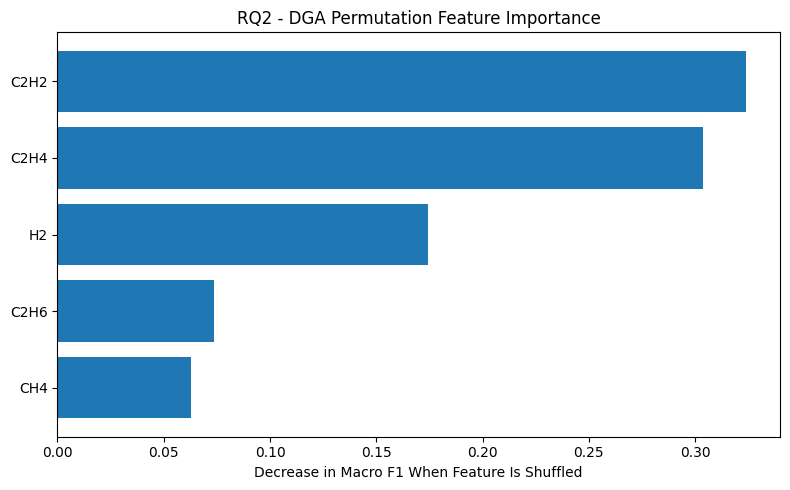

In [ ]:
# RQ2 - Step 1: Permutation Feature Importance

import pandas as pd
import matplotlib.pyplot as plt

from sklearn.inspection import permutation_importance

# Compute permutation importance values using the trained Random Forest model on the already-inspected holdout set (exploratory)
importance = permutation_importance(
    model,
    X_test,
    y_test,
    scoring="f1_macro",
    n_repeats=20,
    random_state=42,
    n_jobs=-1
)

# Aggregate mean and standard deviation of importance scores into a sorted DataFrame
importance_df = pd.DataFrame({
    "DGA Gas": X_test.columns,
    "Mean Importance": importance.importances_mean,
    "Standard Deviation": importance.importances_std
}).sort_values("Mean Importance", ascending=False)

# Print the importance levels
display(importance_df.round(4))

# Plot the horizontal bar chart showing permutation feature importance levels for each DGA gas
plt.figure(figsize=(8, 5))
plt.barh(
    importance_df["DGA Gas"],
    importance_df["Mean Importance"]
)
plt.gca().invert_yaxis()
plt.xlabel("Decrease in Macro F1 When Feature Is Shuffled")
plt.title("RQ2 - DGA Permutation Feature Importance")
plt.tight_layout()
plt.show()

In [ ]:
# RQ2 - Step 2: Complete DGA feature importance

# Display all 5 DGA gas importance scores in a clear tabular format
print("All five DGA gas importance values:")
display(importance_df.to_string(index=False))

# Print count to confirm all 5 gases are processed
print("\nNumber of gases:", len(importance_df))

# Export the permutation importance results to a CSV file for reporting
importance_df.to_csv(
    "RQ2_DGA_Permutation_Importance.csv",
    index=False
)

All five DGA gas importance values:


'DGA Gas  Mean Importance  Standard Deviation\n   C2H2         0.323702            0.043417\n   C2H4         0.303669            0.037249\n     H2         0.174315            0.039839\n   C2H6         0.073819            0.033567\n    CH4         0.062644            0.020323'


Number of gases: 5


SHAP values shape: (50, 5, 6)
Model classes: ['D1' 'D2' 'PD' 'T1' 'T2' 'T3']


,DGA Gas,Mean Absolute SHAP
4,C2H2,0.10430
3,C2H4,0.08548
0,H2,0.05182
2,C2H6,0.03766
1,CH4,0.02728


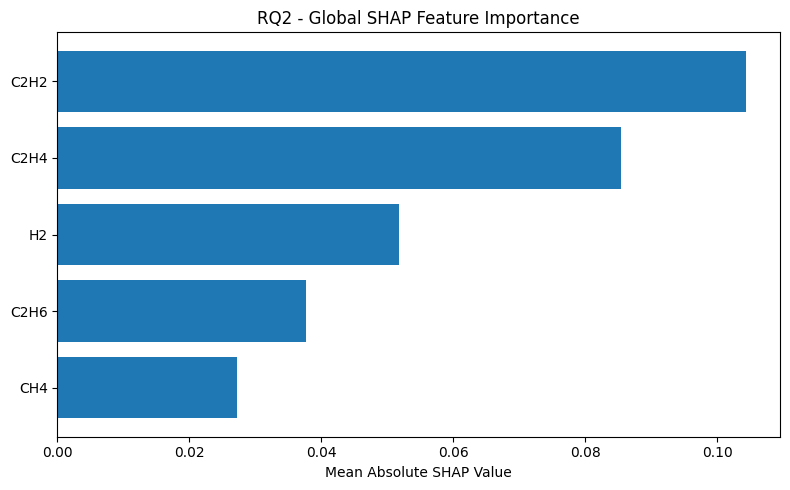

In [ ]:
# RQ2 - Step 3: SHAP for multiclass Random Forest

import shap
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Construct a tree SHAP explainer on the trained Random Forest model
explainer = shap.TreeExplainer(model)

# Extract a manageable sample size (first 50 test rows) for SHAP explanation
X_explain = X_test.iloc[:50].copy()
shap_values = explainer.shap_values(X_explain)

# Reshape SHAP array outputs to maintain standard formatting: (samples, features, classes)
if isinstance(shap_values, list):
    values = np.stack(shap_values, axis=-1)
else:
    values = np.asarray(shap_values)

# Print dimensions and class list attributes of computed SHAP outputs
print("SHAP values shape:", values.shape)
print("Model classes:", model.classes_)

# Calculate overall global feature importance as the mean absolute SHAP value
overall_importance = np.abs(values).mean(axis=(0, 2))

# Structure calculated SHAP importance into a sorted pandas DataFrame
shap_importance = pd.DataFrame({
    "DGA Gas": X_explain.columns,
    "Mean Absolute SHAP": overall_importance
}).sort_values("Mean Absolute SHAP", ascending=False)

# Display the SHAP importance table
display(shap_importance.round(5))

# Plot the global mean absolute SHAP values per feature
plt.figure(figsize=(8, 5))
plt.barh(
    shap_importance["DGA Gas"],
    shap_importance["Mean Absolute SHAP"]
)
plt.gca().invert_yaxis()
plt.xlabel("Mean Absolute SHAP Value")
plt.title("RQ2 - Global SHAP Feature Importance")
plt.tight_layout()
plt.show()

### SHAP global ranking stability across retrained models
Five Random Forest fits use overlapping subsets of the **training** data and a common 50-observation explanation sample drawn from the already-explored holdout. This measures internal global **ranking stability**, not independent external replication, stability of individual explanations, or prediction accuracy.

In [ ]:
# RQ2 - Step 4: SHAP Explanation Stability
# Uses cross-validation folds on the training dataset to examine internal ranking stability on a fixed, already-inspected sample.

import numpy as np
import pandas as pd
import shap

from sklearn.model_selection import StratifiedKFold
from sklearn.ensemble import RandomForestClassifier
from scipy.stats import spearmanr
from itertools import combinations

# Define the gas features
features = ["H2", "CH4", "C2H6", "C2H4", "C2H2"]

# Setup the same stratified 5-fold splits as step 5
cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

rankings = []

# Perform iterative cross-validation to gather fold-specific SHAP scores
for fold, (train_idx, val_idx) in enumerate(
    cv.split(X_train, y_train), start=1
):
    X_fold_train = X_train.iloc[train_idx]
    y_fold_train = y_train.iloc[train_idx]

    # Fit a new classifier model on this training fold split
    rf = RandomForestClassifier(
        n_estimators=200,
        random_state=42 + fold,
        class_weight="balanced"
    )
    rf.fit(X_fold_train, y_fold_train)

    # Generate SHAP value explanations for the fixed test observations
    explainer = shap.TreeExplainer(rf)
    values = explainer.shap_values(X_test.iloc[:50])

    if isinstance(values, list):
        values = np.stack(values, axis=-1)
    else:
        values = np.asarray(values)

    # Calculate feature scores for this fold and append
    mean_abs = np.abs(values).mean(axis=(0, 2))
    rankings.append(mean_abs)

rankings = np.array(rankings)

# Display importance scores recorded across each fold
stability_df = pd.DataFrame(
    rankings,
    columns=features,
    index=[f"Fold {i}" for i in range(1, 6)]
)

display(stability_df.round(5))

spearman_scores = []
jaccard_scores = []

# Calculate pairwise similarity (Spearman rho and Jaccard) between fold metrics to evaluate consistency
for i, j in combinations(range(5), 2):
    rho, _ = spearmanr(rankings[i], rankings[j])
    spearman_scores.append(rho)

    top_i = set(np.argsort(rankings[i])[-3:])
    top_j = set(np.argsort(rankings[j])[-3:])

    jaccard = len(top_i & top_j) / len(top_i | top_j)
    jaccard_scores.append(jaccard)

# Print metrics evaluating the SHAP model's feature rank stability
print("Mean Spearman correlation:",
      round(np.mean(spearman_scores), 4))

print("Mean top-3 Jaccard similarity:",
      round(np.mean(jaccard_scores), 4))

,H2,CH4,C2H6,C2H4,C2H2
Fold 1,0.04989,0.02608,0.03871,0.08479,0.10152
Fold 2,0.05219,0.02597,0.03571,0.08509,0.10318
Fold 3,0.05024,0.02664,0.03619,0.08544,0.10042
Fold 4,0.04994,0.02936,0.04020,0.08954,0.09587
Fold 5,0.05005,0.02699,0.03805,0.08634,0.10338


Mean Spearman correlation: 1.0
Mean top-3 Jaccard similarity: 1.0


In [ ]:
# RQ2: compare rankings, not incompatible metric magnitudes
perm = importance_df[['DGA Gas', 'Mean Importance']].copy()
perm['Permutation Rank'] = perm['Mean Importance'].rank(ascending=False, method='min').astype(int)
shap_r = shap_importance[['DGA Gas', 'Mean Absolute SHAP']].copy()
shap_r['SHAP Rank'] = shap_r['Mean Absolute SHAP'].rank(ascending=False, method='min').astype(int)
rank_comparison = perm.merge(shap_r, on='DGA Gas').sort_values('Permutation Rank')
display(rank_comparison.round(5))


,DGA Gas,Mean Importance,Permutation Rank,Mean Absolute SHAP,SHAP Rank
0,C2H2,0.32370,1,0.10430,1
1,C2H4,0.30367,2,0.08548,2
2,H2,0.17431,3,0.05182,3
3,C2H6,0.07382,4,0.03766,4
4,CH4,0.06264,5,0.02728,5


### Explainability Stability and Limitations

Both global SHAP and permutation importance identify similar influential DGA gases in classification, particularly highlighting **acetylene (C₂H₂)** and **ethylene (C₂H₄)** as the most critical predictors.

While the observed feature-ranking stability achieved a perfect consistency score (Spearman rho of 1.0 and Jaccard similarity of 1.0) under our retraining setup, this stability remains strictly conditional on the available sample size and the specific evaluation procedure. These metrics represent global statistical correlations within this dataset; they do not establish direct causal physical influence or guarantee generalization to independent utility datasets with different sensor types or environmental conditions.

## 4. Consolidated preliminary findings

**RQ1.** Four baseline supervised models are compared on the **587-row deduplicated primary dataset** with an exploratory stratified holdout. See live outputs for exact accuracy, balanced accuracy, macro-F1, class-specific recall, and training-only cross-validation scores. The 589-row analysis is retained solely as a duplicate-handling sensitivity comparison.

**RQ2.** Permutation importance and SHAP provide exploratory feature-attribution rankings for the fitted primary Random Forest. Re-evaluate ranking stability after every rerun; attribution does not imply causation.

**Limits.** Original measurement units, fault-label definitions, reuse permissions, and transformer independence are unverified. These results do not establish field performance or deployment safety.

## 5. Methodological and documentation integrity

1. **Duplicates:** The 587-row deduplicated dataset is the primary exploratory baseline; 589-row results are recalculated as sensitivity analysis. This reduces exact-duplicate leakage risk but cannot guarantee transformer independence.
2. **Validation:** Five-fold stratified cross-validation is computed only within training data for the Random Forest. The four-model comparison uses the same exploratory holdout; **model selection is not nested within cross-validation**, and the holdout is not an untouched final evaluation.
3. **Units and labels:** ppm/μL/L units and IEC/IEEE-derived labeling are **unconfirmed**, pending upstream source documentation. Standards are contextual references only.
4. **Operational safety:** Inspect current per-class recall and confusion matrices, particularly thermal-fault categories, before considering any operational use. Independent external/asset-level validation and human engineering review are required.

## Summary of data cleaning and validation

| Step | Procedure | Status |
|---|---|---|
| 1 | Load public DGA workbook; inspect missing values and exact duplicates | Calculated live |
| 2 | Remove exact duplicate rows for primary exploratory dataset | 589 to 587 expected; verify live |
| 3 | Stratified 80:20 split and four-model comparison | Recalculated live on 587-row primary dataset |
| 4 | Training-only five-fold RF cross-validation | Recalculated live |
| 5 | SHAP, permutation importance, and ranking stability | Recalculated live |
| 6 | Verify units, original sources, licensing, fault labels and asset independence | Pending maintainer/source evidence |

## Resources and provenance

- [Secondary dataset repository — alan-456/transformer-fault-dataset](https://github.com/alan-456/transformer-fault-dataset)
- [Project-hosted copy — M640-Transformer-AI-Capstone](https://github.com/irurama2018-coder/M640-Transformer-AI-Capstone)
- IEC 60599, *Guide to the interpretation of dissolved and free gases analysis* (background standard; **not verified label provenance**).
- IEEE C57.104, *Guide for the Interpretation of Gases Generated in Oil-Immersed Transformers* (background standard; **not verified label provenance**).

The original dataset's measurement units, individual observation sources, licensing, labeling method, and asset independence remain unconfirmed. Confirm these with the source owner before making stronger claims or redistributing data.